# Per-taster models: combined analysis

Reruns the single-taster location models (Roger Voss, Anne Krebiehl MW, Anna Lee C. Iijima, plus Michael Schachner
from slides 7-8) under **one identical protocol**, so the tasters can be compared directly:

| Setting | Value (same for every taster) |
|---|---|
| Splits | shared `data_clean/splits` (70/15/15, stratified by country), filtered to the taster |
| Features | TF-IDF, words + bigrams, `min_df=3`, `max_df=0.9`, `sublinear_tf`, fit on the taster's training reviews only |
| Classes | labels with at least 20 training reviews for that taster |
| Model | logistic regression, grid over `C` x `class_weight` |
| Selection rule | best **validation macro-F1** (one rule for every taster and target) |
| Comparisons | majority class, general all-taster model (as in `tfidf_baselines.ipynb`) |
| Reporting | validation for selection, untouched **test** set for final numbers, bootstrap 95% CIs |

In [1]:
import time
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from joblib import parallel_config
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.multiclass import OneVsRestClassifier

SEED = 42
TASTERS = ["Roger Voss", "Anne Krebiehl MW", "Anna Lee C. Iijima", "Michael Schachner"]
SHORT = {"Roger Voss": "Voss", "Anne Krebiehl MW": "Krebiehl", "Anna Lee C. Iijima": "Iijima",
         "Michael Schachner": "Schachner"}
TARGETS = ["country", "province", "region_1"]
MIN_TRAIN_REVIEWS = 20          # per-taster class cutoff
GLOBAL_MIN_TRAIN_REVIEWS = 70   # same cutoff as tfidf_baselines.ipynb
GRID = [{"C": C, "class_weight": cw} for cw in [None, "balanced"] for C in [0.3, 1, 3, 10, 30, 100]]
N_BOOT = 1000
N_JOBS = 6  # change depending on number of cores
BLUE, LIGHT, GREY = "#2a78d6", "#8fb6e8", "#c9c8c3"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

## Load
Taster names are normalised because some contain non-breaking spaces (e.g. `Anne Krebiehl\xa0MW`).

In [2]:
split_dir = Path("data_clean/splits")
full = {}
for name in ["train", "val", "test"]:
    df = pd.read_parquet(split_dir / f"{name}.parquet")
    df["taster"] = df["taster_name"].str.replace("\xa0", " ").str.strip()
    full[name] = df

data = {t: {s: full[s][full[s]["taster"] == t].reset_index(drop=True) for s in full} for t in TASTERS}
pd.DataFrame({t: {s: len(d) for s, d in data[t].items()} for t in TASTERS}).T

,train,val,test
Roger Voss,16500,3544,3512
Anne Krebiehl MW,2282,510,496
Anna Lee C. Iijima,2838,578,601
Michael Schachner,9838,2098,2108


## What each taster covers
Share of training reviews by country (top 4). The majority-class baseline is the first column.

In [3]:
coverage = {}
for t in TASTERS:
    shares = data[t]["train"]["country"].value_counts(normalize=True).head(4)
    coverage[SHORT[t]] = ", ".join(f"{c} {p:.0%}" for c, p in shares.items())
pd.Series(coverage, name="top countries").to_frame()

,top countries
Voss,"France 73%, Portugal 22%, Austria 5%, Italy 0%"
Krebiehl,"Austria 59%, France 39%, England 2%"
Iijima,"US 56%, Germany 39%, Romania 1%, Croatia 1%"
Schachner,"Spain 43%, Chile 29%, Argentina 25%, Uruguay 1%"


## General model (all tasters)
Trained once on every taster's training reviews with the exact settings of `tfidf_baselines.ipynb`,
then evaluated on each taster's reviews. This answers: does training on one critic beat a model that has seen everyone?

In [4]:
full_train = full["train"]
global_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=20000)
X_full_train = global_vectorizer.fit_transform(full_train["description"])
global_models = {}
for target in TARGETS:
    start = time.perf_counter()
    counts = full_train[target].value_counts()
    mask = full_train[target].isin(counts[counts >= GLOBAL_MIN_TRAIN_REVIEWS].index).to_numpy()
    model = OneVsRestClassifier(LogisticRegression(C=10, solver="liblinear"), n_jobs=N_JOBS)
    with parallel_config(max_nbytes=None):
        model.fit(X_full_train[mask], full_train[target].to_numpy()[mask])
    global_models[target] = model
    print(f"{target}: {time.perf_counter() - start:.0f}s")

country: 7s


province: 17s


region_1: 25s


## Per-taster features and classes

In [5]:
def make_vectorizer():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)

feats, keep, class_summary = {}, {}, []
for t in TASTERS:
    vec = make_vectorizer()
    tr = data[t]["train"]
    feats[t] = {"vectorizer": vec, "train": vec.fit_transform(tr["description"])}
    for s in ["val", "test"]:
        feats[t][s] = vec.transform(data[t][s]["description"])
    for target in TARGETS:
        counts = tr[target].value_counts()
        keep[t, target] = counts[counts >= MIN_TRAIN_REVIEWS].index
        class_summary.append({
            "taster": SHORT[t], "target": target,
            "all_classes": tr[target].nunique(),
            "kept_classes": len(keep[t, target]),
            "pct_missing": tr[target].isna().mean() * 100,
            "pct_rows_kept": tr[target].isin(keep[t, target]).mean() * 100,
            "vocab": feats[t]["train"].shape[1],
        })
pd.DataFrame(class_summary).set_index(["taster", "target"]).round(1)

all_classes  kept_classes  pct_missing  pct_rows_kept  \
taster    target                                                            
Voss      country             7             4          0.0           99.9   
          province           83            28          0.0           97.4   
          region_1          319           106         27.2           65.5   
Krebiehl  country             3             3          0.3           99.7   
          province           27            15          0.3           95.2   
          region_1            2             2         61.2           38.8   
Iijima    country            16             5          0.0           97.6   
          province           62             9          0.0           93.1   
          region_1           28             8         43.9           54.2   
Schachner country            11             8          0.1           99.6   
          province           80            29          0.1           97.0   
          region_1          140            45         30.9           64.1   

                    vocab  
taster    target           
Voss      country   26390  
          province  26390  
          region_1  26390  
Krebiehl  country    8499  
          province   8499  
          region_1   8499  
Iijima    country    8341  
          province   8341  
          region_1   8341  
Schachner country   24625  
          province  24625  
          region_1  24625

In [6]:
def subset(t, split, target, X=None):
    df = data[t][split]
    mask = df[target].isin(keep[t, target]).to_numpy()
    X = feats[t][split] if X is None else X
    return X[mask], df[target].to_numpy()[mask], mask

def macro_f1(t, target, y, pred):
    # averaged over the taster's kept classes only, so a never-predicted class counts as 0
    return f1_score(y, pred, labels=keep[t, target], average="macro", zero_division=0)

## Tuning (validation)
Every taster and target uses the same 12-point grid. The selected setting is the best validation macro-F1;
the best-accuracy setting is shown alongside it to make the trade-off visible.

In [7]:
tuning = []
for t in TASTERS:
    for target in TARGETS:
        Xt, yt, _ = subset(t, "train", target)
        Xv, yv, _ = subset(t, "val", target)
        if len(set(yt)) < 2:
            continue
        for params in GRID:
            pred = LogisticRegression(max_iter=5000, **params).fit(Xt, yt).predict(Xv)
            tuning.append({
                "taster": SHORT[t], "target": target, "C": params["C"],
                "class_weight": params["class_weight"] or "none",
                "accuracy": accuracy_score(yv, pred), "macro_F1": macro_f1(t, target, yv, pred),
            })
tuning = pd.DataFrame(tuning)
picks = pd.concat({m: tuning.loc[tuning.groupby(["taster", "target"])[m].idxmax()].set_index(["taster", "target"])
                   for m in ["macro_F1", "accuracy"]}, names=["picked_by"])
picks.round(3)

C class_weight  accuracy  macro_F1
picked_by taster    target                                          
macro_F1  Iijima    country     1.0     balanced     0.761     0.599
                    province    1.0     balanced     0.604     0.265
                    region_1    0.3     balanced     0.401     0.220
          Krebiehl  country     0.3     balanced     0.843     0.737
                    province    3.0     balanced     0.527     0.258
                    region_1   30.0     balanced     0.943     0.880
          Schachner country     0.3     balanced     0.612     0.423
                    province   30.0     balanced     0.412     0.236
                    region_1    3.0     balanced     0.303     0.177
          Voss      country    30.0     balanced     0.817     0.611
                    province   10.0     balanced     0.566     0.369
                    region_1    3.0     balanced     0.353     0.249
accuracy  Iijima    country    30.0     balanced     0.766     0.469
                    province    1.0         none     0.694     0.160
                    region_1   10.0     balanced     0.616     0.215
          Krebiehl  country     3.0         none     0.861     0.573
                    province   30.0     balanced     0.539     0.245
                    region_1   30.0     balanced     0.943     0.880
          Schachner country     3.0     balanced     0.637     0.399
                    province   30.0         none     0.425     0.184
                    region_1  100.0     balanced     0.391     0.165
          Voss      country     3.0         none     0.832     0.504
                    province   10.0     balanced     0.566     0.369
                    region_1  100.0     balanced     0.379     0.218

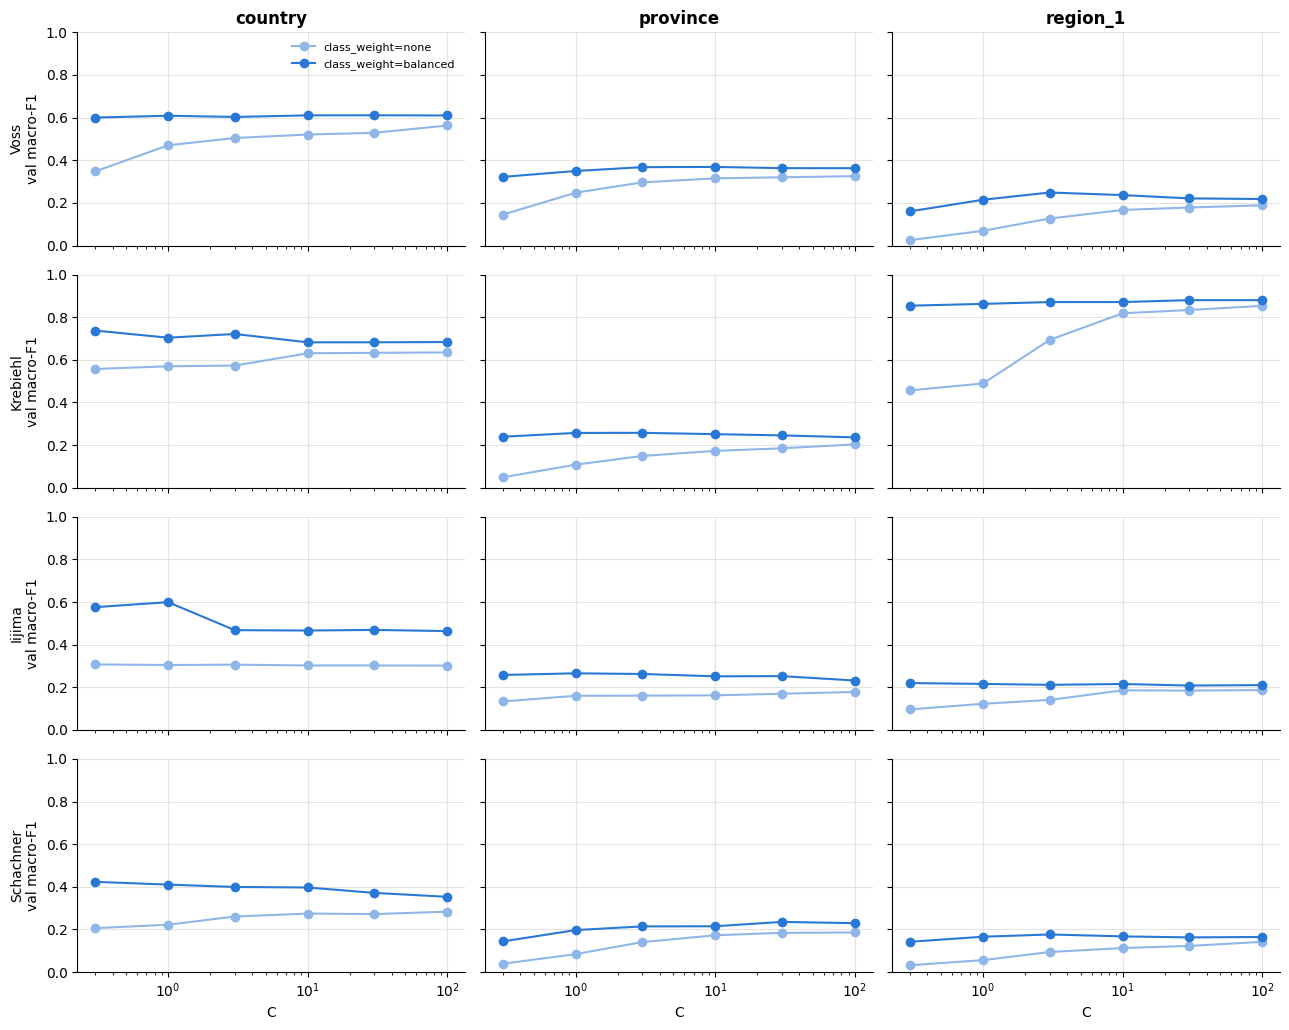

In [8]:
fig, axes = plt.subplots(len(TASTERS), len(TARGETS), figsize=(13, 2.6 * len(TASTERS)), sharex=True, sharey=True)
for i, t in enumerate(TASTERS):
    for j, target in enumerate(TARGETS):
        ax = axes[i, j]
        for cw, color in [("none", LIGHT), ("balanced", BLUE)]:
            rows = tuning[(tuning["taster"] == SHORT[t]) & (tuning["target"] == target) & (tuning["class_weight"] == cw)]
            ax.plot(rows["C"], rows["macro_F1"], marker="o", color=color, label=f"class_weight={cw}")
        ax.set(xscale="log", ylim=(0, 1))
        if i == 0: ax.set_title(target)
        if j == 0: ax.set_ylabel(f"{SHORT[t]}\nval macro-F1")
        if i == len(TASTERS) - 1: ax.set_xlabel("C")
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()

## Fit the selected models

In [9]:
models = {}
for t in TASTERS:
    for target in TARGETS:
        key = (SHORT[t], target)
        if key not in picks.loc["macro_F1"].index:
            continue
        p = picks.loc[("macro_F1", *key)]
        Xt, yt, _ = subset(t, "train", target)
        cw = None if p["class_weight"] == "none" else p["class_weight"]
        models[t, target] = {
            "dummy": DummyClassifier(strategy="most_frequent").fit(Xt, yt),
            "author": LogisticRegression(C=p["C"], class_weight=cw, max_iter=5000).fit(Xt, yt),
        }

## Evaluation
`train_acc` is shown for the author model so the generalisation gap is visible.
CIs are percentile bootstraps over the evaluation reviews (1,000 resamples).

In [10]:
MODEL_NAMES = {"dummy": "Majority class", "general": "General model (all tasters)",
               "author": "Author model (LR)"}

def predict_all(t, split, target):
    Xs, ys, mask = subset(t, split, target)
    desc = data[t][split]["description"][mask]
    m = models[t, target]
    return ys, {
        "dummy": m["dummy"].predict(Xs),
        "general": global_models[target].predict(global_vectorizer.transform(desc)),
        "author": m["author"].predict(Xs),
    }

def bootstrap_ci(t, target, y, pred, rng):
    n = len(y)
    accs, f1s = [], []
    for _ in range(N_BOOT):
        idx = rng.integers(0, n, n)
        accs.append((y[idx] == pred[idx]).mean())
        f1s.append(macro_f1(t, target, y[idx], pred[idx]))
    return np.percentile(accs, [2.5, 97.5]), np.percentile(f1s, [2.5, 97.5])

def evaluate(split, with_ci=False):
    rng = np.random.default_rng(SEED)
    rows = []
    for (t, target), m in models.items():
        ys, preds = predict_all(t, split, target)
        for name, pred in preds.items():
            row = {"taster": SHORT[t], "target": target, "model": MODEL_NAMES[name], "n": len(ys),
                   "accuracy": accuracy_score(ys, pred), "macro_F1": macro_f1(t, target, ys, pred)}
            if name == "author":
                Xt, yt, _ = subset(t, "train", target)
                row["train_acc"] = accuracy_score(yt, m["author"].predict(Xt))
            if with_ci and name in ("author", "general", "dummy"):
                (a_lo, a_hi), (f_lo, f_hi) = bootstrap_ci(t, target, ys, pred, rng)
                row.update(acc_lo=a_lo, acc_hi=a_hi, f1_lo=f_lo, f1_hi=f_hi)
            rows.append(row)
    return pd.DataFrame(rows).set_index(["taster", "target", "model"])

val_results = evaluate("val")
val_results.round(3)

n  accuracy  macro_F1  \
taster    target   model                                                   
Voss      country  Majority class               3538     0.731     0.211   
                   General model (all tasters)  3538     0.820     0.572   
                   Author model (LR)            3538     0.817     0.611   
          province Majority class               3445     0.251     0.014   
                   General model (all tasters)  3445     0.533     0.299   
                   Author model (LR)            3445     0.566     0.369   
          region_1 Majority class               2330     0.094     0.002   
                   General model (all tasters)  2330     0.347     0.116   
                   Author model (LR)            2330     0.353     0.249   
Krebiehl  country  Majority class                509     0.599     0.250   
                   General model (all tasters)   509     0.745     0.517   
                   Author model (LR)             509     0.843     0.737   
          province Majority class                486     0.399     0.038   
                   General model (all tasters)   486     0.471     0.154   
                   Author model (LR)             486     0.527     0.258   
          region_1 Majority class                194     0.840     0.457   
                   General model (all tasters)   194     0.938     0.864   
                   Author model (LR)             194     0.943     0.880   
Iijima    country  Majority class                564     0.539     0.140   
                   General model (all tasters)   564     0.741     0.301   
                   Author model (LR)             564     0.761     0.599   
          province Majority class                533     0.561     0.080   
                   General model (all tasters)   533     0.651     0.179   
                   Author model (LR)             533     0.604     0.265   
          region_1 Majority class                294     0.548     0.088   
                   General model (all tasters)   294     0.565     0.142   
                   Author model (LR)             294     0.401     0.220   
Schachner country  Majority class               2094     0.433     0.076   
                   General model (all tasters)  2094     0.591     0.242   
                   Author model (LR)            2094     0.612     0.423   
          province Majority class               2047     0.243     0.013   
                   General model (all tasters)  2047     0.377     0.155   
                   Author model (LR)            2047     0.412     0.236   
          region_1 Majority class               1337     0.230     0.008   
                   General model (all tasters)  1337     0.388     0.121   
                   Author model (LR)            1337     0.303     0.177   

                                                train_acc  
taster    target   model                                   
Voss      country  Majority class                     NaN  
                   General model (all tasters)        NaN  
                   Author model (LR)                0.998  
          province Majority class                     NaN  
                   General model (all tasters)        NaN  
                   Author model (LR)                0.948  
          region_1 Majority class                     NaN  
                   General model (all tasters)        NaN  
                   Author model (LR)                0.891  
Krebiehl  country  Majority class                     NaN  
                   General model (all tasters)        NaN  
                   Author model (LR)                0.917  
          province Majority class                     NaN  
                   General model (all tasters)        NaN  
                   Author model (LR)                0.960  
          region_1 Majority class                     NaN  
                   General model (all tasters)        NaN  
                   Aut

## Test set (final numbers)

In [11]:
test_results = evaluate("test", with_ci=True)
test_results.round(3)

n  accuracy  macro_F1  \
taster    target   model                                                   
Voss      country  Majority class               3509     0.732     0.211   
                   General model (all tasters)  3509     0.817     0.533   
                   Author model (LR)            3509     0.816     0.685   
          province Majority class               3434     0.237     0.014   
                   General model (all tasters)  3434     0.539     0.325   
                   Author model (LR)            3434     0.561     0.380   
          region_1 Majority class               2283     0.087     0.002   
                   General model (all tasters)  2283     0.331     0.115   
                   Author model (LR)            2283     0.343     0.243   
Krebiehl  country  Majority class                496     0.623     0.256   
                   General model (all tasters)   496     0.742     0.519   
                   Author model (LR)             496     0.841     0.778   
          province Majority class                476     0.374     0.036   
                   General model (all tasters)   476     0.464     0.169   
                   Author model (LR)             476     0.532     0.342   
          region_1 Majority class                178     0.910     0.476   
                   General model (all tasters)   178     0.933     0.848   
                   Author model (LR)             178     0.949     0.831   
Iijima    country  Majority class                580     0.545     0.141   
                   General model (all tasters)   580     0.729     0.294   
                   Author model (LR)             580     0.767     0.360   
          province Majority class                557     0.551     0.079   
                   General model (all tasters)   557     0.607     0.167   
                   Author model (LR)             557     0.589     0.365   
          region_1 Majority class                308     0.539     0.088   
                   General model (all tasters)   308     0.584     0.197   
                   Author model (LR)             308     0.448     0.332   
Schachner country  Majority class               2099     0.434     0.076   
                   General model (all tasters)  2099     0.594     0.246   
                   Author model (LR)            2099     0.600     0.339   
          province Majority class               2032     0.271     0.015   
                   General model (all tasters)  2032     0.405     0.159   
                   Author model (LR)            2032     0.426     0.244   
          region_1 Majority class               1358     0.242     0.009   
                   General model (all tasters)  1358     0.409     0.138   
                   Author model (LR)            1358     0.320     0.192   

                                                acc_lo  acc_hi  f1_lo  f1_hi  \
taster    target   model                                                       
Voss      country  Majority class                0.716   0.747  0.209  0.214   
                   General model (all tasters)   0.805   0.830  0.487  0.588   
                   Author model (LR)             0.803   0.828  0.613  0.739   
          province Majority class                0.223   0.252  0.013  0.014   
                   General model (all tasters)   0.522   0.555  0.301  0.346   
                   Author model (LR)             0.543   0.577  0.353  0.403   
          region_1 Majority class                0.077   0.098  0.001  0.002   
                   General model (all tasters)   0.312   0.350  0.104  0.124   
                   Author model (LR)             0.324   0.362  0.212  0.257   
Krebiehl  country  Majority class                0.579   0.663  0.244  0.266   
                   General model (all tasters)   0.706   0.782  0.496  0.544   
                   Author model (LR)             0.806   0.871  0.654  0.861   
          province Majority class         

### Headline table: country, test set

In [12]:
country = test_results.xs("country", level="target")
headline = pd.DataFrame({
    "n_test": country.xs(MODEL_NAMES["author"], level="model")["n"],
    "majority_acc": country.xs(MODEL_NAMES["dummy"], level="model")["accuracy"],
    "general_acc": country.xs(MODEL_NAMES["general"], level="model")["accuracy"],
    "author_acc": country.xs(MODEL_NAMES["author"], level="model")["accuracy"],
    "author_acc_CI": country.xs(MODEL_NAMES["author"], level="model").apply(
        lambda r: f"[{r.acc_lo:.3f}, {r.acc_hi:.3f}]", axis=1),
    "majority_F1": country.xs(MODEL_NAMES["dummy"], level="model")["macro_F1"],
    "general_F1": country.xs(MODEL_NAMES["general"], level="model")["macro_F1"],
    "author_F1": country.xs(MODEL_NAMES["author"], level="model")["macro_F1"],
    "author_F1_CI": country.xs(MODEL_NAMES["author"], level="model").apply(
        lambda r: f"[{r.f1_lo:.3f}, {r.f1_hi:.3f}]", axis=1),
    "train_acc": country.xs(MODEL_NAMES["author"], level="model")["train_acc"],
})
headline["gap"] = headline["train_acc"] - headline["author_acc"]
headline.round(3)

,n_test,majority_acc,general_acc,author_acc,author_acc_CI,majority_F1,general_F1,author_F1,author_F1_CI,train_acc,gap
taster,,,,,,,,,,,
Voss,3509,0.732,0.817,0.816,"[0.803, 0.828]",0.211,0.533,0.685,"[0.613, 0.739]",0.998,0.182
Krebiehl,496,0.623,0.742,0.841,"[0.806, 0.871]",0.256,0.519,0.778,"[0.654, 0.861]",0.917,0.077
Iijima,580,0.545,0.729,0.767,"[0.728, 0.802]",0.141,0.294,0.360,"[0.299, 0.446]",0.880,0.113
Schachner,2099,0.434,0.594,0.600,"[0.577, 0.621]",0.076,0.246,0.339,"[0.285, 0.384]",0.746,0.146


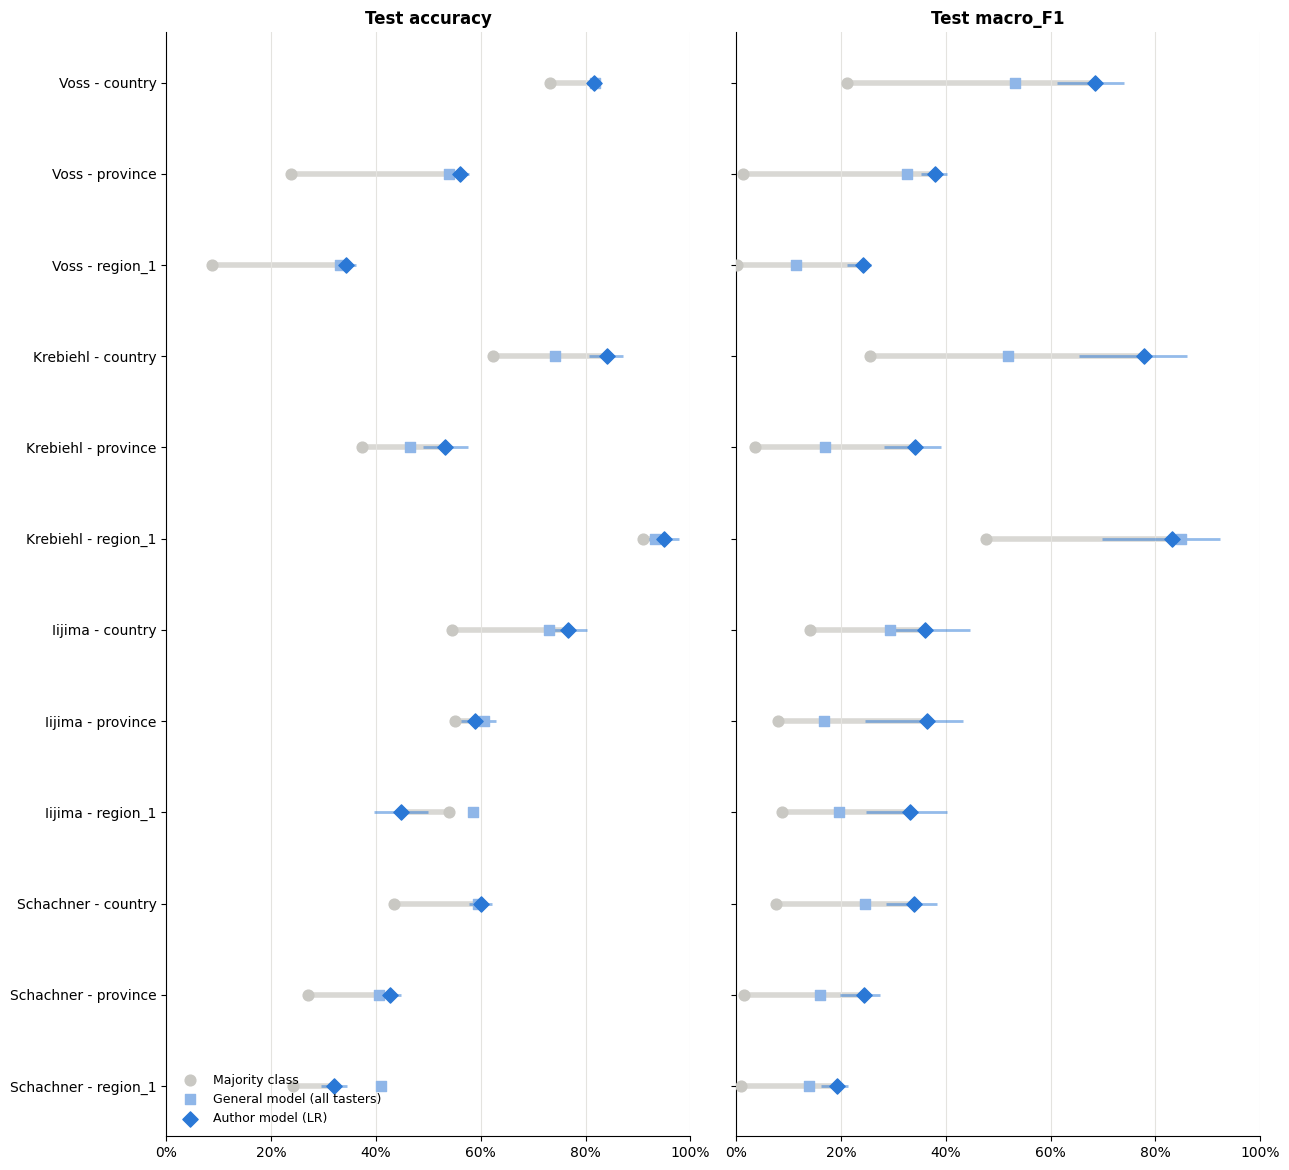

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 0.9 * len(TASTERS) * len(TARGETS) + 1), sharey=True)
order = [(SHORT[t], tg) for t in TASTERS for tg in TARGETS if (t, tg) in models]
labels = [f"{t} - {tg}" for t, tg in order]
ypos = np.arange(len(order))[::-1]
for ax, metric in zip(axes, ["accuracy", "macro_F1"]):
    for k, (name, color, marker) in enumerate([("dummy", GREY, "o"), ("general", LIGHT, "s"), ("author", BLUE, "D")]):
        vals = [test_results.loc[(t, tg, MODEL_NAMES[name]), metric] for t, tg in order]
        if name == "author":
            lo = [test_results.loc[(t, tg, MODEL_NAMES[name]), "acc_lo" if metric == "accuracy" else "f1_lo"] for t, tg in order]
            hi = [test_results.loc[(t, tg, MODEL_NAMES[name]), "acc_hi" if metric == "accuracy" else "f1_hi"] for t, tg in order]
            ax.hlines(ypos, lo, hi, color=BLUE, linewidth=2, alpha=0.5)
        if name == "dummy":
            author_vals = [test_results.loc[(t, tg, MODEL_NAMES["author"]), metric] for t, tg in order]
            ax.hlines(ypos, vals, author_vals, color="#d9d8d4", linewidth=4, zorder=0)
        ax.scatter(vals, ypos, color=color, marker=marker, s=60, zorder=3, label=MODEL_NAMES[name])
    ax.set(xlim=(0, 1), title=f"Test {metric}")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos, labels)
axes[0].legend(frameon=False, loc="lower left", fontsize=9)
plt.tight_layout()

## Per-class recall (country, test)
Which countries each author model actually gets right. Small classes drive the gap between accuracy and macro-F1.

In [14]:
rows = []
for t in TASTERS:
    ys, preds = predict_all(t, "test", "country")
    for cls in keep[t, "country"]:
        m = ys == cls
        rows.append({"taster": SHORT[t], "country": cls, "n_test": int(m.sum()),
                     "recall": (preds["author"][m] == cls).mean() if m.any() else np.nan,
                     "general_recall": (preds["general"][m] == cls).mean() if m.any() else np.nan})
per_class = pd.DataFrame(rows).set_index(["taster", "country"])
per_class.round(3)

n_test  recall  general_recall
taster    country                                  
Voss      France       2568   0.879           0.933
          Portugal      781   0.661           0.525
          Austria       145   0.579           0.407
          Italy          15   0.467           0.067
Krebiehl  Austria       309   0.851           0.754
          France        178   0.837           0.758
          England         9   0.556           0.000
Iijima    US            316   0.766           0.823
          Germany       251   0.805           0.649
          Romania         3   0.000           0.000
          Croatia         7   0.143           0.000
          Hungary         3   0.000           0.000
Schachner Spain         910   0.691           0.759
          Chile         613   0.561           0.546
          Argentina     532   0.517           0.404
          Uruguay        14   0.357           0.000
          Italy           6   0.500           0.167
          US              6   0.667           0.833
          Mexico         10   0.000           0.000
          Brazil          8   0.000           0.000

## Ablation: remove place and grape names
How much of each taster's signal is just names? Every country, province, region and variety name in the training data
(plus country adjectives and common grape short forms) is removed from the text, then the country model is
retrained with the **same selected `C` / `class_weight`**. Names shorter than 4 characters and generic labels
(e.g. "Red Blend", "Rosé") are kept to avoid deleting ordinary words. This is an approximate scrub, not a perfect one.

In [15]:
DEMONYMS = ["american", "argentine", "argentinian", "australian", "austrian", "bulgarian", "canadian", "chilean",
            "croatian", "english", "french", "german", "greek", "hungarian", "israeli", "italian", "new zealand",
            "portuguese", "romanian", "south african", "spanish", "slovenian", "uruguayan", "georgian", "moldovan",
            "lebanese", "turkish", "mexican"]
GRAPE_SHORT = ["cab", "cabernet", "pinot", "sauvignon", "zin", "chard", "malbecs", "grüner", "gruner", "syrah",
               "shiraz", "merlot", "riesling", "blaufränkisch", "carmenère", "carmenere", "tempranillo", "garnacha",
               "sangiovese", "nebbiolo", "chenin", "sb", "gsm", "côte", "cote", "côtes", "cotes", "château", "chateau"]
GENERIC = {"rosé", "rose", "red", "white", "sparkling", "vital", "port", "champagne blend"}

names = set()
for col in ["country", "province", "region_1", "region_2", "variety"]:
    names |= set(full_train[col].dropna().str.lower())
names = {n for n in names if len(n) >= 4 and "blend" not in n and n not in GENERIC}
names |= set(DEMONYMS) | set(GRAPE_SHORT)
pattern = re.compile(r"(?<!\w)(" + "|".join(re.escape(n) for n in sorted(names, key=len, reverse=True)) + r")(?!\w)")

def scrub(texts):
    return texts.str.lower().str.replace(pattern, " ", regex=True)

print(len(names), "names removed")
example = data["Michael Schachner"]["val"]["description"].iloc[0]
print(example, "\n->", scrub(pd.Series([example]))[0])

2182 names removed
Shiny pink in color, with youthful, crisp aromas of cherry and watermelon. Zesty and fresh on the tongue, with spunky cherry and raspberry flavors that finish with natural sweetness. Candied to an extent, but mostly it's fresh and balanced. 
-> shiny pink in color, with youthful, crisp aromas of cherry and watermelon. zesty and fresh on the tongue, with spunky cherry and raspberry flavors that finish with natural sweetness. candied to an extent, but mostly it's fresh and balanced.


In [16]:
ablation = []
for t in TASTERS:
    target = "country"
    vec = make_vectorizer()
    Xtr = vec.fit_transform(scrub(data[t]["train"]["description"]))
    Xte = vec.transform(scrub(data[t]["test"]["description"]))
    Xt, yt, _ = subset(t, "train", target, Xtr)
    Xs, ys, _ = subset(t, "test", target, Xte)
    params = models[t, target]["author"].get_params()
    scrubbed = LogisticRegression(C=params["C"], class_weight=params["class_weight"], max_iter=5000).fit(Xt, yt)
    pred = scrubbed.predict(Xs)
    ablation.append({
        "taster": SHORT[t],
        "majority": test_results.loc[(SHORT[t], target, MODEL_NAMES["dummy"]), "accuracy"],
        "names_removed": accuracy_score(ys, pred),
        "all_words": test_results.loc[(SHORT[t], target, MODEL_NAMES["author"]), "accuracy"],
        "names_removed_F1": macro_f1(t, target, ys, pred),
        "all_words_F1": test_results.loc[(SHORT[t], target, MODEL_NAMES["author"]), "macro_F1"],
    })
ablation = pd.DataFrame(ablation).set_index("taster")
ablation["share_of_gain_from_names"] = (ablation["all_words"] - ablation["names_removed"]) / (
    ablation["all_words"] - ablation["majority"])
ablation.round(3)

,majority,names_removed,all_words,names_removed_F1,all_words_F1,share_of_gain_from_names
taster,,,,,,
Voss,0.732,0.776,0.816,0.580,0.685,0.480
Krebiehl,0.623,0.839,0.841,0.763,0.778,0.009
Iijima,0.545,0.762,0.767,0.308,0.360,0.023
Schachner,0.434,0.504,0.600,0.237,0.339,0.580


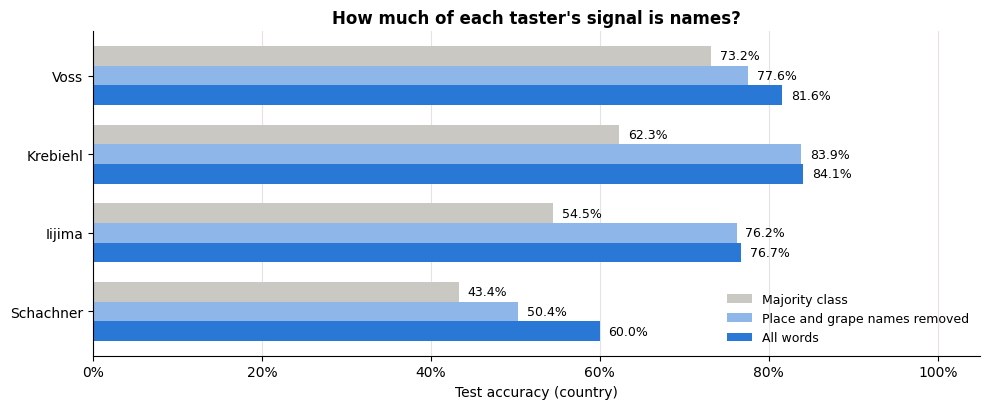

In [17]:
fig, ax = plt.subplots(figsize=(10, 0.8 * len(TASTERS) + 1))
y = np.arange(len(ablation))[::-1]
h = 0.25
for k, (col, color, label) in enumerate([("majority", GREY, "Majority class"),
                                         ("names_removed", LIGHT, "Place and grape names removed"),
                                         ("all_words", BLUE, "All words")]):
    ax.barh(y + (1 - k) * h, ablation[col], height=h, color=color, label=label)
    for yy, v in zip(y + (1 - k) * h, ablation[col]):
        ax.text(v + 0.01, yy, f"{v:.1%}", va="center", fontsize=9)
ax.set_yticks(y, ablation.index)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlim=(0, 1.05), xlabel="Test accuracy (country)", title="How much of each taster's signal is names?")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()

## Top words per country (author models)

In [18]:
def top_words(t, target="country", n=8):
    m = models[t, target]["author"]
    words = feats[t]["vectorizer"].get_feature_names_out()
    coef = m.coef_ if len(m.classes_) > 2 else np.vstack([-m.coef_[0], m.coef_[0]])
    return pd.DataFrame({cls: words[np.argsort(c)[::-1][:n]] for cls, c in zip(m.classes_, coef)}).T

for t in TASTERS:
    print(f"=== {t}")
    display(top_words(t))

=== Roger Voss


,0,1,2,3,4,5,6,7
Austria,screwcap,grüner,zweigelt,blaufränkisch,glass stopper,stopper,pepper,glass
France,champagne,malbec,the vintage,château,smoky,cru,chablis,merlot
Italy,1997,soave,pinot grigio,grigio,riserva,brunello,of,has fresh
Portugal,douro,port,alvarinho,alentejo,quinta,arinto,portugal,touriga


=== Anne Krebiehl MW


,0,1,2,3,4,5,6,7
Austria,cherry,pepper,savory,zesty,white,light,white pepper,green pear
England,creamy,apple,tart,autolysis,tiny,autolytic,bubbles,crisp
France,dry,dry and,is dry,peach,sweetness,the dry,bitter,off dry


=== Anna Lee C. Iijima


,0,1,2,3,4,5,6,7
Croatia,croatian,malvasia,flower,grassy,hay,note,aeration,at 13
Germany,riesling,mineral,kabinett,now,spätlese,through,dry riesling,sweet
Hungary,tokaji,honey,has,hefty,tokaj,hefty dose,peel,orange peel
Romania,romanian,romania,from romania,brisk acidity,green,noir is,wine concentrated,for
US,chardonnay,franc,cabernet franc,apple,cabernet,gewürztraminer,in,bit


=== Michael Schachner


,0,1,2,3,4,5,6,7
Argentina,malbec,this malbec,blackberry,berry,lychee,torrontés,flavors,of malbec
Brazil,foamy,yeasty,merlot,bready,and lychee,tannic,abrasive,soda
Chile,herbal,olive,carmenère,green,chilean,herbs,syrah,chile
Italy,sangiovese,it,brunello,its,from,chianti,tuscan,cabernet
Mexico,baja,nebbiolo,melon,sauvignon,sauvignon blanc,it finishes,blanc,sweet
Spain,garnacha,tempranillo,rioja,drink,nectarine,fresh,through,monastrell
US,oregon,it,in the,southern oregon,cherries,some,in,southern
Uruguay,tannat,this tannat,uruguayan,of tannat,uruguay,savory,bitter on,while this


# Slide figures
One message per chart, built from the results above and saved to `figures/`.

In [ ]:
from sklearn.metrics import confusion_matrix

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SLIDE_ORDER = ["Krebiehl", "Voss", "Iijima", "Schachner"]
INK, MUTED = "#2b2a27", "#6b6a66"

def test_predictions(t, target):
    """Author-model test predictions with the review rows they came from."""
    Xs, ys, mask = subset(t, "test", target)
    rows = data[t]["test"][mask].copy()
    rows["pred"] = models[t, target]["author"].predict(Xs)
    rows["correct"] = rows["pred"] == rows[target]
    return rows

## Slide figures: per-critic models (one message per chart)
`per_critic_f1.png`: macro-F1 of the all-critic model vs the critic-specific model.
`per_critic_names.png`: share of each critic's gain over guessing that comes from place and grape names.

In [ ]:
def simple_axes(ax):
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0, labelsize=15)
    ax.tick_params(axis="y", labelsize=12)
    ax.spines["left"].set_visible(False)
    ax.set_yticks([])

# Chart 1: macro-F1, all-critic model vs this critic's own model
f1 = headline.loc[SLIDE_ORDER, ["general_F1", "author_F1"]]
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(f1))
w = 0.38
for k, (col, color, label) in enumerate([("general_F1", GREY, "Model trained on all critics"),
                                         ("author_F1", BLUE, "Model trained on this critic")]):
    ax.bar(x + (k - 0.5) * w, f1[col], width=w, color=color, label=label)
    for xx, v in zip(x + (k - 0.5) * w, f1[col]):
        ax.text(xx, v + 0.015, f"{v:.2f}", ha="center", fontsize=15, fontweight="bold" if k else None,
                color=INK if k else MUTED)
ax.set_xticks(x, f1.index)
ax.set(ylim=(0, 0.9))
ax.set_ylabel("Macro-F1 (country, test)", fontsize=13)
simple_axes(ax)
ax.legend(frameon=False, fontsize=12, loc="upper right")
fig.savefig(FIG_DIR / "per_critic_f1.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

# Chart 2: share of the gain over guessing that comes from place and grape names
share = ablation.loc[SLIDE_ORDER, "share_of_gain_from_names"].clip(lower=0)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(share.index, share, color=[BLUE if v > 0.25 else GREY for v in share], width=0.6)
for bar, v in zip(bars, share):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{v:.0%}", ha="center", fontsize=18, fontweight="bold",
            color=INK)
ax.set(ylim=(0, 0.75))
ax.set_ylabel("Share of the model's gain\nthat comes from names", fontsize=13)
simple_axes(ax)
fig.savefig(FIG_DIR / "per_critic_names.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## Slide figure: overview of the four critics
x = share of the model's gain that comes from place and grape names (ablation above);
y = how much the critic's own model beats always guessing their main country.
Under each name: the three highest-ranked descriptor words (not place or grape names) from that critic's
top-words table above, picked by hand. Saved to `figures/overview_critics.png`.

In [ ]:
DESCRIPTORS = {  # highest-ranked non-name words in each critic's top-words table above
    "Krebiehl": "pepper, savory, autolysis",
    "Iijima": "mineral, apple, grassy",
    "Voss": "screwcap, glass stopper, smoky",
    "Schachner": "herbal, olive, blackberry",
}
ov = ablation.loc[SLIDE_ORDER].copy()
ov["gain"] = ov["all_words"] - ov["majority"]
ov["names"] = ov["share_of_gain_from_names"].clip(lower=0)
LABEL_POS = {"Krebiehl": (8, -30), "Iijima": (8, 8), "Voss": (8, -12), "Schachner": (-8, 10)}  # offsets in points
LABEL_HA = {"Schachner": "right"}

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(ov["names"], ov["gain"], s=60, color=BLUE, zorder=3)
for c, r in ov.iterrows():
    dx, dy = LABEL_POS[c]
    ha = LABEL_HA.get(c, "left")
    ax.annotate(c, (r["names"], r["gain"]), xytext=(dx, dy + 6), textcoords="offset points", fontsize=12, ha=ha)
    ax.annotate(DESCRIPTORS[c], (r["names"], r["gain"]), xytext=(dx, dy - 8), textcoords="offset points",
                fontsize=10, color=MUTED, ha=ha)
ax.set(xlim=(-0.02, 0.7), ylim=(0, 0.3))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Share of gain from place and grape names", fontsize=12)
ax.set_ylabel("Accuracy gain over guessing main country", fontsize=12)
ax.grid(True, color="#e4e3df")
fig.savefig(FIG_DIR / "overview_critics.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## Finding 1: Riesling crosses borders
Iijima's errors are almost all US <-> Germany, and most of those are Riesling: the model reads a Finger Lakes
Riesling as a Mosel one. Riesling is also the weaker grape for every critic who reviews a lot of it.
Saved to `figures/finding_riesling.png`.

In [ ]:
country_preds = {SHORT[t]: test_predictions(t, "country") for t in TASTERS}
prov_preds = {SHORT[t]: test_predictions(t, "province") for t in TASTERS}
prov_country = {SHORT[t]: data[t]["train"].dropna(subset=["province", "country"])
                .groupby("province")["country"].agg(lambda s: s.mode()[0]) for t in TASTERS}

pair_rows = []
for c, df in country_preds.items():
    err = df[~df["correct"]]
    a, b = err.groupby(["country", "pred"]).size().idxmax()
    pair = err[err["country"].isin([a, b]) & err["pred"].isin([a, b])]
    grapes = pair["variety"].value_counts()
    pair_rows.append({"critic": c, "confused_pair": f"{a} <-> {b}", "pair_errors": len(pair),
                      "share_of_all_errors": len(pair) / len(err), "top_grape": grapes.index[0],
                      "top_grape_share": grapes.iloc[0] / len(pair)})
confusions = pd.DataFrame(pair_rows).set_index("critic").loc[SLIDE_ORDER]
display(confusions.round(3))

riesling_rows = []
for c, df in country_preds.items():
    r = df["variety"].eq("Riesling")
    if r.sum() >= 30:
        riesling_rows.append({"critic": c, "riesling_n": int(r.sum()), "riesling_acc": df.loc[r, "correct"].mean(),
                              "other_acc": df.loc[~r, "correct"].mean()})
riesling = pd.DataFrame(riesling_rows).set_index("critic")
display(riesling.round(3))

iij = prov_preds["Iijima"]
iij_err = iij[~iij["correct"]]
ny_to_de = iij_err[(iij_err["province"] == "New York") & (iij_err["pred"].map(prov_country["Iijima"]) == "Germany")]
print(f"Iijima New York reviews predicted as a German province: {len(ny_to_de)} of "
      f"{(iij['province'] == 'New York').sum()} ({ny_to_de['variety'].eq('Riesling').mean():.0%} Riesling)")

# Headline number for the slide: how often Iijima's US wines get called German, Riesling vs everything else
us = country_preds["Iijima"].query("country == 'US'")
is_riesling = us["variety"].eq("Riesling")
us_called_german = pd.DataFrame({
    "n": [int(is_riesling.sum()), int((~is_riesling).sum())],
    "called_germany": [us.loc[is_riesling, "pred"].eq("Germany").mean(), us.loc[~is_riesling, "pred"].eq("Germany").mean()],
}, index=["US Riesling", "Other US wines"])
display(us_called_german.round(3))

In [ ]:
# Simple slide chart: one comparison, one message
fig, ax = plt.subplots(figsize=(11, 4.2))
vals = us_called_german["called_germany"]
labels = [f"{idx}\n(n={n})" for idx, n in zip(us_called_german.index, us_called_german["n"])]
bars = ax.barh(labels, vals, color=[BLUE, GREY], height=0.55)
ax.invert_yaxis()
for bar, v in zip(bars, vals):
    ax.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.0%}", va="center", fontsize=22, fontweight="bold",
            color=INK)
ax.set(xlim=(0, 0.6))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Share the model labels as German (Iijima, test set)", fontsize=13)
ax.tick_params(axis="y", labelsize=15, length=0)
ax.tick_params(axis="x", labelsize=12)
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
fig.savefig(FIG_DIR / "finding_riesling.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

In [ ]:
# Simple slide chart: Iijima's 2x2 country confusion matrix (US vs Germany), row-normalised
df = country_preds["Iijima"]
df = df[df["country"].isin(["US", "Germany"])]
labels = ["US", "Germany"]
cm = confusion_matrix(df["country"], df["pred"], labels=labels)
share = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
for i, j in np.ndindex(cm.shape):
    ax.text(j, i, f"{share[i, j]:.0%}\n({cm[i, j]} reviews)", ha="center", va="center", fontsize=17,
            fontweight="bold", color="white" if share[i, j] > 0.55 else INK)
ax.set_xticks(range(2), labels, fontsize=15)
ax.set_yticks(range(2), labels, fontsize=15)
ax.set_xlabel("Model predicted", fontsize=14)
ax.set_ylabel("Actual country", fontsize=14)
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.savefig(FIG_DIR / "confusion_iijima.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## Finding 2: Voss's mistakes stay in France, Schachner's cross the Atlantic
Of the reviews each province model gets wrong, how often is the wrong guess still a province in the right country?
"Random" is that rate if the wrong guess were a random other province the critic covers. The matrices show each
critic's biggest provinces, grouped by country (lines split countries). Saved to `figures/finding_province_errors.png`.

In [ ]:
near_rows = []
for t in TASTERS:
    c = SHORT[t]
    df = prov_preds[c]
    kept_country = pd.Series(list(keep[t, "province"])).map(prov_country[c])
    err = df[~df["correct"]]
    same = (err["pred"].map(prov_country[c]) == err["country"]).mean()
    chance = np.mean([((kept_country == prov_country[c][p]).sum() - 1) / (len(kept_country) - 1)
                      for p in err["province"]])
    near_rows.append({"critic": c, "provinces": len(kept_country), "accuracy": df["correct"].mean(),
                      "errors": len(err), "wrong_but_same_country": same, "random": chance})
near = pd.DataFrame(near_rows).set_index("critic").loc[SLIDE_ORDER]
display(near.round(3))

for c in ["Voss", "Schachner"]:
    err = prov_preds[c][~prov_preds[c]["correct"]]
    top = err.groupby(["province", "pred"]).size().sort_values(ascending=False).head(4)
    print(f"--- {c}: most common province mistakes (top grape)")
    for (a, b), n in top.items():
        g = err[(err["province"] == a) & (err["pred"] == b)]["variety"].value_counts()
        print(f"  {a} -> {b}: {n} reviews ({g.index[0]} {g.iloc[0] / n:.0%})")

In [ ]:
# Simple slide chart: one bar per critic, dashed line = random
crit = ["Voss", "Schachner"]
vals = near.loc[crit, "wrong_but_same_country"]
rand = near.loc[crit, "random"].mean()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(crit, vals, color=[BLUE, GREY], width=0.55)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{v:.0%}", ha="center", fontsize=22, fontweight="bold",
            color=INK)
ax.axhline(rand, color=MUTED, linestyle="--", linewidth=1.5)
ax.text(0.5, rand + 0.012, f"random ≈ {rand:.0%}", ha="center", fontsize=12, color=MUTED)
ax.set(ylim=(0, 0.75))
ax.set_ylabel("Wrong province guesses\nstill in the right country", fontsize=13)
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", length=0, labelsize=15)
ax.spines["left"].set_visible(False)
ax.set_yticks([])
fig.savefig(FIG_DIR / "finding_province_errors.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## Optional: decision tree comparison
Not run in the saved results (it is slow on the larger tasters and never beat logistic regression in the
original notebooks). Set `RUN_TREES = True` and run this cell to add a decision tree with the same settings as
`tfidf_baselines.ipynb` (`max_depth=30`, `min_samples_leaf=5`) to the test comparison.

In [ ]:
RUN_TREES = False

if RUN_TREES:
    from sklearn.tree import DecisionTreeClassifier

    tree_rows = []
    for (t, target), m in models.items():
        Xt, yt, _ = subset(t, "train", target)
        Xs, ys, _ = subset(t, "test", target)
        tree = DecisionTreeClassifier(max_depth=30, min_samples_leaf=5, random_state=SEED).fit(Xt, yt)
        m["tree"] = tree
        pred = tree.predict(Xs)
        tree_rows.append({
            "taster": SHORT[t], "target": target,
            "tree_train_acc": accuracy_score(yt, tree.predict(Xt)),
            "tree_acc": accuracy_score(ys, pred),
            "tree_F1": macro_f1(t, target, ys, pred),
            "author_acc": test_results.loc[(SHORT[t], target, MODEL_NAMES["author"]), "accuracy"],
            "author_F1": test_results.loc[(SHORT[t], target, MODEL_NAMES["author"]), "macro_F1"],
        })
    display(pd.DataFrame(tree_rows).set_index(["taster", "target"]).round(3))
else:
    print("Skipped: set RUN_TREES = True to fit the decision trees.")

## Summary
Filled in from the outputs above; rerun the notebook and update if anything changes.

In [19]:
summary = headline[["n_test", "majority_acc", "author_acc", "general_acc", "majority_F1", "author_F1", "general_F1", "gap"]].copy()
summary["names_removed_acc"] = ablation["names_removed"]
summary.round(3)

,n_test,majority_acc,author_acc,general_acc,majority_F1,author_F1,general_F1,gap,names_removed_acc
taster,,,,,,,,,
Voss,3509,0.732,0.816,0.817,0.211,0.685,0.533,0.182,0.776
Krebiehl,496,0.623,0.841,0.742,0.256,0.778,0.519,0.077,0.839
Iijima,580,0.545,0.767,0.729,0.141,0.360,0.294,0.113,0.762
Schachner,2099,0.434,0.600,0.594,0.076,0.339,0.246,0.146,0.504
